## Imports


In [1]:
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import pandas as pd
import timm
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


/win_d/Programming/University/pistachio-image-classification/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters


In [2]:
ds_path="../../pistachio-edited/"
train_path=f"{ds_path}/train"
valid_path=f"{ds_path}/valid"
test_path=f"{ds_path}/test"
size=(224,224)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 1. Data loading


In [3]:
transform=transforms.Compose([
	transforms.Grayscale(num_output_channels=3),
	transforms.Resize(size),
	transforms.ToTensor()
])

train_ds=ImageFolder(root=train_path,transform=transform)
valid_ds = ImageFolder(root=valid_path, transform=transform)
test_ds = ImageFolder(root=test_path, transform=transform)

train_ld=DataLoader(train_ds,batch_size=32,shuffle=True)
valid_ld = DataLoader(valid_ds, batch_size=32, shuffle=True)
test_ld = DataLoader(test_ds, batch_size=32, shuffle=True)

### visualization


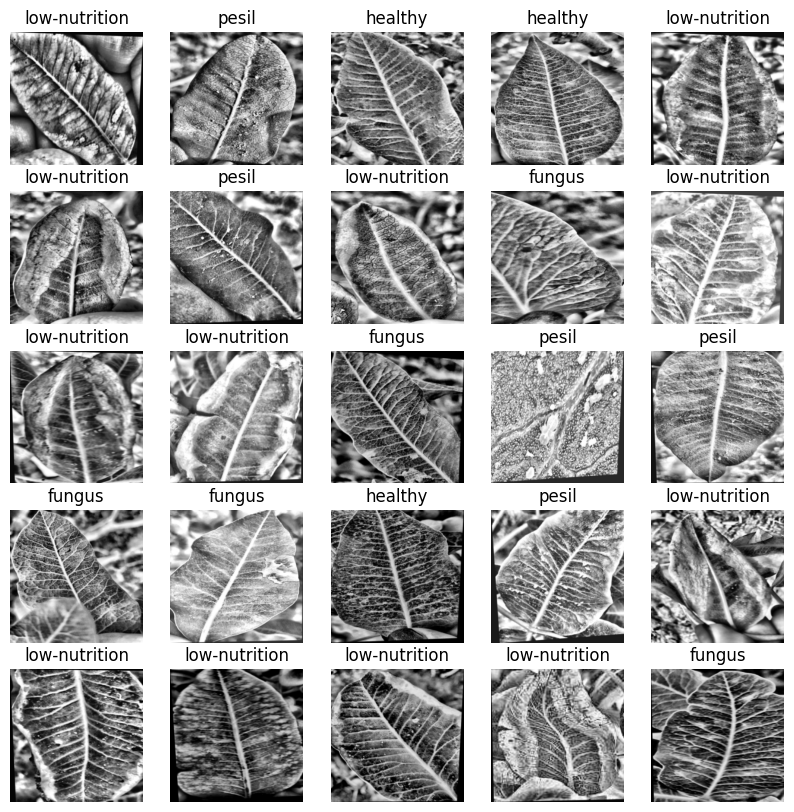

In [11]:
# Get a batch
images, labels = next(iter(train_ld))
classes=train_ds.classes
# Denormalize if needed (not needed now since images are just [0,1])
# Convert from (C, H, W) → (H, W, C) for matplotlib
# Plot 5×5 grid
plt.figure(figsize=(10, 10))
for i in range(25):
    img = images[i].permute(1, 2, 0)  # C,H,W → H,W,C
    plt.subplot(5, 5, i + 1)
    plt.imshow(img.numpy())
    plt.title(f"{classes[labels[i].item()]}")
    plt.axis("off")
plt.show()

## 2. Model


### custom model


In [4]:
class LeafClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv=nn.Conv2d(3,32,kernel_size=3,padding=1)
        self.maxpool=nn.MaxPool2d(2)
        self.conv2=nn.Conv2d(32,64,kernel_size=3,padding=1)
        self.flat=nn.Flatten()
        self.fc1=nn.Linear(64 * 56 * 56, 128)
        self.fc2=nn.Linear(128,4)
    
    def forward(self, x):
        x = nn.ReLU()(self.conv(x))
        x = self.maxpool(x)
        x = nn.ReLU()(self.conv2(x))
        x = self.maxpool(x)
        x = self.flat(x)
        x = nn.ReLU()(self.fc1(x))
        x = self.fc2(x)
        return x
model = LeafClassifier()

### bit model


In [5]:
model = timm.create_model('resnetv2_50x1_bit', pretrained=True)
model.reset_classifier(num_classes=4)

In [6]:
dummy = torch.randn(1, 3, 224, 224)  # single fake image
# print(model)
out = model(dummy)
print(out.shape)


torch.Size([1, 4])


## 3. Training


In [15]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
model.to(device)

num_epoches = 20
history = {
	"acc": [],
	"loss": [],
	"val_acc": [],
	"val_loss": []
}
for epoch in range(num_epoches):
    model.train()
    total_loss = 0
    correct_train = 0
    total_train = 0
    for images, labels in train_ld:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()           # Step 1: reset gradients
        outputs = model(images)         # Step 2: forward pass
        loss = loss_fn(outputs, labels) # Step 3: compute loss
        loss.backward()                 # Step 4: backpropagation
        optimizer.step()                # Step 5: update weights
        
        total_loss += loss.item()
        
        _, predicted = torch.max(outputs, 1)
        correct_train += (predicted == labels).sum().item()
        total_train += labels.size(0)
    
    model.eval()
    correct = 0
    total = 0
    val_loss = 0
    with torch.no_grad():
        for images, labels in valid_ld:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)               # Shape: [B, 4]
            loss = loss_fn(outputs, labels)
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)  # Get class with highest score
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            
    
    avg_loss = total_loss / len(train_ld)
    accuracy = correct_train / total_train
    valid_accuracy = correct / total
    validation_loss = val_loss / len(train_ld)
    history["acc"].append(accuracy)
    history["loss"].append(avg_loss)
    history["val_acc"].append(valid_accuracy)
    history["val_loss"].append(validation_loss)
 
    print(f"Epoch {epoch+1}/{num_epoches}, Accuracy: {accuracy:.4f}, Validation accuracy: {valid_accuracy:.4f}, Loss: {avg_loss:.4f}, Validation loss: {validation_loss:.4f}")    

Epoch 1/20, Accuracy: 0.9555, Validation accuracy: 0.8341, Loss: 0.1424, Validation loss: 0.0673
Epoch 2/20, Accuracy: 0.9667, Validation accuracy: 0.8146, Loss: 0.1169, Validation loss: 0.0659
Epoch 3/20, Accuracy: 0.9701, Validation accuracy: 0.8195, Loss: 0.0883, Validation loss: 0.0649
Epoch 4/20, Accuracy: 0.9711, Validation accuracy: 0.7512, Loss: 0.0839, Validation loss: 0.0902
Epoch 5/20, Accuracy: 0.9652, Validation accuracy: 0.8439, Loss: 0.1149, Validation loss: 0.0794
Epoch 6/20, Accuracy: 0.9589, Validation accuracy: 0.8098, Loss: 0.1245, Validation loss: 0.0741
Epoch 7/20, Accuracy: 0.9819, Validation accuracy: 0.7854, Loss: 0.0567, Validation loss: 0.0870
Epoch 8/20, Accuracy: 0.9838, Validation accuracy: 0.8098, Loss: 0.0443, Validation loss: 0.0818
Epoch 9/20, Accuracy: 0.9809, Validation accuracy: 0.7854, Loss: 0.0495, Validation loss: 0.0873
Epoch 10/20, Accuracy: 0.9956, Validation accuracy: 0.8293, Loss: 0.0115, Validation loss: 0.0769
Epoch 11/20, Accuracy: 0.9741

### output figure


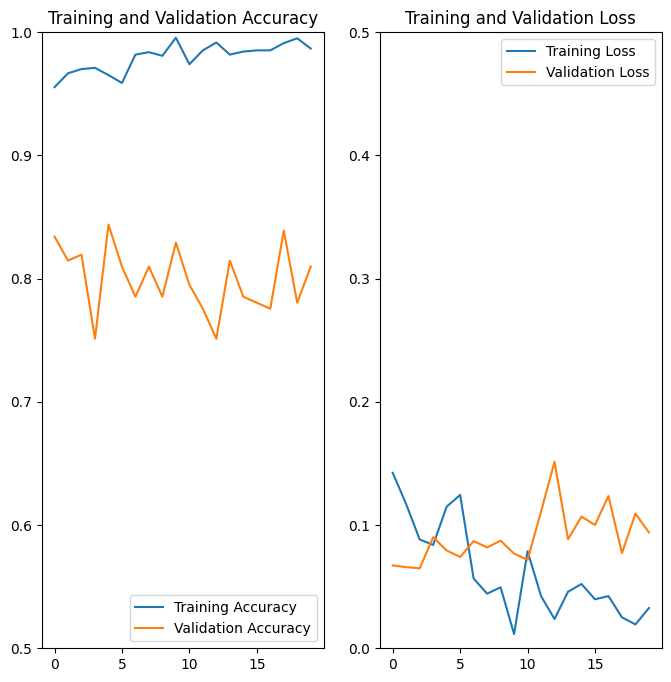

In [22]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(num_epoches), history["acc"], label='Training Accuracy')
plt.plot(range(num_epoches), history["val_acc"], label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.ylim(0.5, 1)

plt.subplot(1, 2, 2)
plt.plot(range(num_epoches), history["loss"], label='Training Loss')
plt.plot(range(num_epoches), history["val_loss"], label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.ylim(0, 0.5)
plt.show()

## 4. Metrics


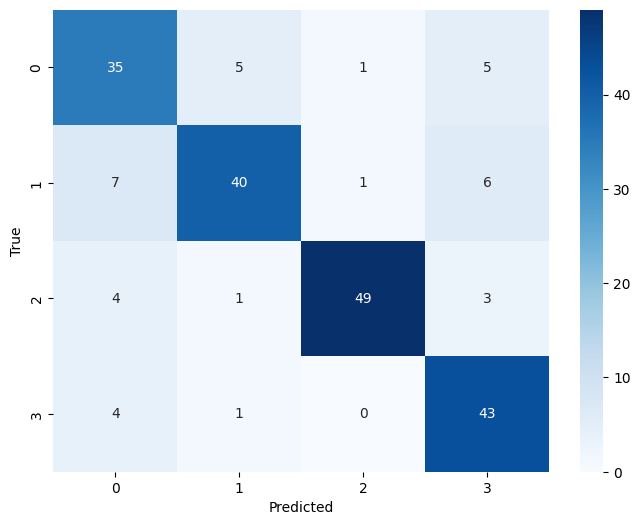

               precision    recall  f1-score     support
fungus          0.700000  0.760870  0.729167   46.000000
healthy         0.851064  0.740741  0.792079   54.000000
low-nutrition   0.960784  0.859649  0.907407   57.000000
pesil           0.754386  0.895833  0.819048   48.000000
accuracy        0.814634  0.814634  0.814634    0.814634
macro avg       0.816559  0.814273  0.811925  205.000000
weighted avg    0.825037  0.814634  0.816344  205.000000


In [9]:
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in valid_ld:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
cm = confusion_matrix(all_labels, all_preds)
# Plot confusion matrix nicely
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

#print(f"Confusion Matrix: {cm}")
report_df = pd.DataFrame(classification_report(all_labels, all_preds, target_names=valid_ds.classes, output_dict=True)).transpose()
print(report_df)

## 5. Testing


In [23]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_ld:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    test_accuracy = correct / total
    print(f"test accuracy: {test_accuracy:.4f}")

test accuracy: 0.6986


## 6. Save and Load


In [27]:
# Save model weights
torch.save(model.state_dict(), '../models/BiT/bit_torch.pth')

In [ ]:
# Load
model = LeafClassifier()          # make sure you create the model architecture first
model.load_state_dict(torch.load("model_weights.pth"))
model.eval()

## 7. Grad-CAM


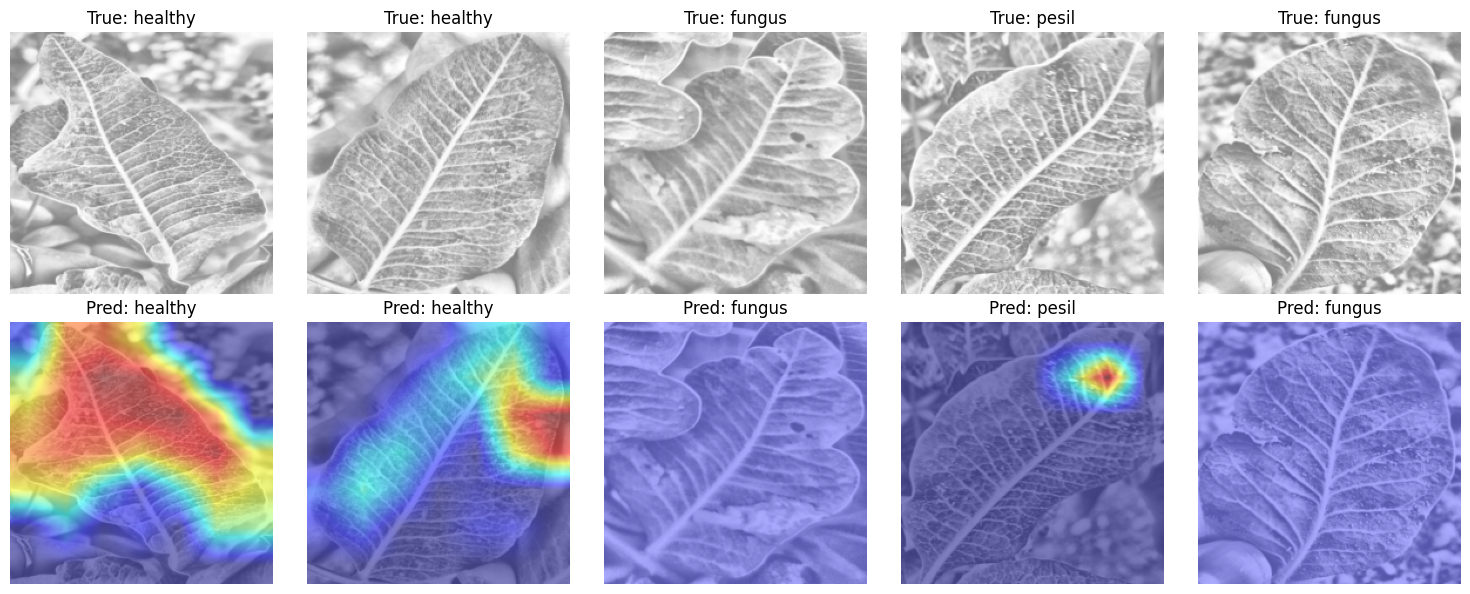

In [61]:

# Your model (already trained and on eval mode)
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classes=test_ds.classes

# Choose the target layer for Grad-CAM (depends on model)
# For timm BiT models like resnetv2_50x1_bit, this works:
target_layers = [model.stages[-1].blocks[-1].conv3]

# Create GradCAM object
cam = GradCAM(model=model, target_layers=target_layers)

# Fetch a batch of images from the test loader
dataiter = iter(test_ld)
images, labels = next(dataiter)
images = images.to(device)

images = images[:5]
labels = labels[:5]
# Predict classes
outputs = model(images)
preds = torch.argmax(outputs, dim=1)

# Prepare input for CAM
targets = [ClassifierOutputTarget(int(p)) for p in preds]
grayscale_cams = cam(input_tensor=images, targets=targets)

# Unnormalize for visualization (adjust if your normalization differs)
mean = torch.tensor([0.5, 0.5, 0.5]).to(device).view(1, 3, 1, 1)
std = torch.tensor([0.5, 0.5, 0.5]).to(device).view(1, 3, 1, 1)
images_norm = images * std + mean
images_np = images_norm.cpu().permute(0, 2, 3, 1).numpy()

# Plot
batch_size = len(images)
fig, axs = plt.subplots(2, batch_size, figsize=(3 * batch_size, 6))

for i in range(batch_size):
    # CAM overlay
    cam_image = show_cam_on_image(images_np[i], grayscale_cams[i], use_rgb=True)

    axs[0, i].imshow(images_np[i])
    axs[0, i].axis('off')
    axs[0, i].set_title(f"True: {classes[labels[i].item()]}")
    
    axs[1, i].imshow(cam_image)
    axs[1, i].axis('off')
    axs[1, i].set_title(f"Pred: {classes[preds[i].item()]}")

plt.tight_layout()
plt.show()